In [26]:
from pathlib import Path
import random

import matplotlib.patches as patches
import matplotlib.pyplot as plt
from PIL import Image

In [27]:
DATA_DIR = Path("../data")
CLASS_NAMES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
COLORS = ["tab:red", "tab:orange", "tab:green", "tab:blue"]

In [28]:
def read_yolo_labels(label_path):
    boxes = []
    for line in label_path.read_text().splitlines():
        if line.strip():
            cls, xc, yc, w, h = line.split()
            boxes.append((int(cls), float(xc), float(yc), float(w), float(h)))
    return boxes


def draw_boxes(ax, image_path, label_path):
    img = Image.open(image_path).convert("RGB")
    width, height = img.size
    ax.imshow(img)
    for cls, xc, yc, w, h in read_yolo_labels(label_path):
        x1, y1 = (xc - w / 2) * width, (yc - h / 2) * height
        ax.add_patch(patches.Rectangle((x1, y1), w * width, h * height, fill=False, edgecolor=COLORS[cls], linewidth=2))
        ax.text(x1, y1 - 5, CLASS_NAMES[cls], color="white", fontsize=9, backgroundcolor=COLORS[cls])
    ax.axis("off")

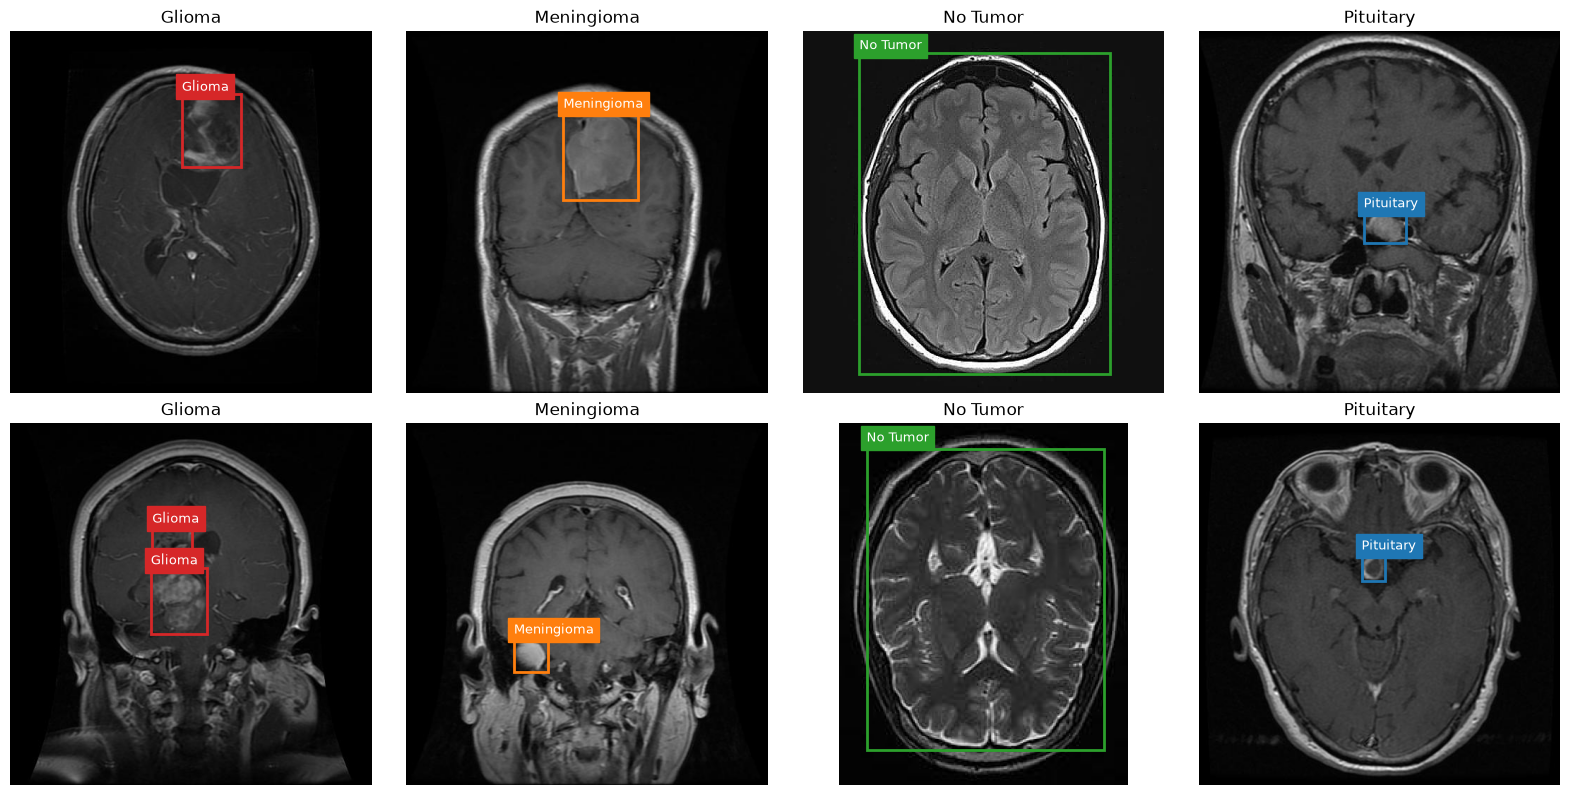

In [29]:
random.seed(42)
samples = []
for class_dir in sorted((DATA_DIR / "Train").iterdir()):
    images = sorted((class_dir / "images").glob("*.jpg"))
    for image_path in random.sample(images, 2):
        samples.append((image_path, class_dir / "labels" / f"{image_path.stem}.txt"))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (image_path, label_path) in zip(axes.T.flat, samples):
    draw_boxes(ax, image_path, label_path)
    ax.set_title(image_path.parent.parent.name)
plt.tight_layout()
plt.show()

In [30]:
IMG_EXTS = {".jpg", ".jpeg", ".png"}

pairs, images_without_label, labels_without_image = [], [], []
for split_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        images = {f.stem: f for f in (class_dir / "images").iterdir() if f.suffix.lower() in IMG_EXTS}
        labels = {f.stem: f for f in (class_dir / "labels").iterdir() if f.suffix == ".txt"}
        pairs += [(images[name], labels[name]) for name in sorted(images.keys() & labels.keys())]
        images_without_label += [images[name] for name in sorted(images.keys() - labels.keys())]
        labels_without_image += [labels[name] for name in sorted(labels.keys() - images.keys())]

print(f"Paires valides : {len(pairs)}")
print(f"Images sans label : {len(images_without_label)}", [p.name for p in images_without_label])
print(f"Labels sans image : {len(labels_without_image)}", [p.name for p in labels_without_image])

Paires valides : 5247
Images sans label : 2 ['image(55).jpg', 'image(61).jpg']
Labels sans image : 2 ['image(53).txt', 'image(60).txt']


In [31]:
from collections import Counter

CLASS_IDS = {name: i for i, name in enumerate(CLASS_NAMES)}


def parse_line(line):
    parts = line.split()
    if len(parts) != 5:
        return None
    try:
        cls = int(parts[0])
        xc, yc, w, h = map(float, parts[1:])
    except ValueError:
        return None
    if not 0 <= cls < len(CLASS_NAMES):
        return None
    if not all(0 <= v <= 1 for v in (xc, yc, w, h)) or w <= 0 or h <= 0:
        return None
    return cls, xc, yc, w, h


clean_pairs = []
invalid_lines, inconsistent_files, discarded = [], [], []

for image_path, label_path in pairs:
    folder_class = CLASS_IDS[image_path.parent.parent.name]
    boxes = []
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        box = parse_line(line)
        if box is None:
            invalid_lines.append((label_path, line))
        else:
            boxes.append(box)

    if any(box[0] != folder_class for box in boxes):
        inconsistent_files.append((image_path, label_path))

    if any(box[0] == folder_class for box in boxes):
        clean_pairs.append((image_path, boxes))
    else:
        discarded.append(image_path)

print(f"Lignes invalides : {len(invalid_lines)}")
print(f"Fichiers avec une boîte d'une autre classe : {len(inconsistent_files)}",
      dict(Counter(p.parent.parent.name for p, _ in inconsistent_files)))
print(f"Images écartées (aucune boîte de leur classe) : {len(discarded)}", [p.name for p in discarded])
print(f"Paires propres : {len(clean_pairs)}")

Lignes invalides : 0
Fichiers avec une boîte d'une autre classe : 272 {'Glioma': 165, 'Meningioma': 106, 'Pituitary': 1}
Images écartées (aucune boîte de leur classe) : 16 ['Te-gl_0043.jpg', 'Tr-gl_1167.jpg', 'gg (278).jpg', 'Tr-me_0023.jpg', 'Tr-me_0119.jpg', 'Tr-me_0385.jpg', 'm (49).jpg', 'm (50).jpg', 'm (51).jpg', 'm (52).jpg', 'm (53).jpg', 'm (54).jpg', 'm (55).jpg', 'm3 (120).jpg', 'p (564).jpg', 'gg (342).jpg']
Paires propres : 5231


In [32]:
import shutil
import pandas as pd

YOLO_DIR = Path("../processed/yolo")
SET_NAMES = {"train": "train", "val": "valid", "test": "test"}

split_df = pd.read_csv("../processed/split.csv")
image_set = {Path(p).resolve(): SET_NAMES[s] for p, s in zip(split_df["path"], split_df["set"])}

shutil.rmtree(YOLO_DIR, ignore_errors=True)
for image_path, boxes in clean_pairs:
    set_name = image_set[image_path.resolve()]
    label_path = image_path.parent.parent / "labels" / f"{image_path.stem}.txt"
    for kind, src in [("images", image_path), ("labels", label_path)]:
        dest = YOLO_DIR / kind / set_name
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dest / src.name)

In [33]:
counts = pd.DataFrame({
    kind: {set_name: len(list((YOLO_DIR / kind / set_name).iterdir())) for set_name in SET_NAMES.values()}
    for kind in ["images", "labels"]
})
counts.loc["total"] = counts.sum()
counts

,images,labels
train,3660,3660
valid,786,786
test,785,785
total,5231,5231


In [34]:
import yaml 

DATA_YAML = YOLO_DIR / 'data.yaml'

data_config = {
    'path': str(YOLO_DIR.resolve()),
    'train': 'images/train',
    'val': 'images/valid',
    'test': 'images/test',
    'nc': len(CLASS_NAMES),
    'names':CLASS_NAMES,
}

DATA_YAML.write_text(yaml.safe_dump(data_config , sort_keys=False , allow_unicode=True))
print(DATA_YAML.read_text())

path: /home/kerymy/Study-DevAI/DiagnosticMultimodal/processed/yolo
train: images/train
val: images/valid
test: images/test
nc: 4
names:
- Glioma
- Meningioma
- No Tumor
- Pituitary



In [35]:
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()

with open(PROJECT_ROOT / 'config' / 'detection.yaml') as f:
    det_config = yaml.safe_load(f)
    
model_name = det_config.pop('model')
det_config["data"] = str(PROJECT_ROOT / det_config["data"])

print(model_name)
det_config

yolov8n.pt


{'data': '/home/kerymy/Study-DevAI/DiagnosticMultimodal/processed/yolo/data.yaml',
 'imgsz': 512,
 'epochs': 50,
 'patience': 10,
 'batch': 16,
 'optimizer': 'auto',
 'lr0': 0.01,
 'seed': 42,
 'deterministic': True,
 'hsv_h': 0.0,
 'hsv_s': 0.0,
 'hsv_v': 0.3,
 'degrees': 10.0,
 'translate': 0.1,
 'scale': 0.3,
 'fliplr': 0.5,
 'flipud': 0.0,
 'mosaic': 1.0,
 'close_mosaic': 10,
 'mixup': 0.0}

In [36]:
import contextlib
import os

import mlflow
from ultralytics import YOLO, settings

EXPERIMENT = "brain-tumor-detection"
os.environ["MLFLOW_TRACKING_URI"] = f"sqlite:///{PROJECT_ROOT / 'mlflow.db'}"
os.environ["MLFLOW_EXPERIMENT_NAME"] = EXPERIMENT
settings.update({"mlflow": True})

mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(PROJECT_ROOT / "mlruns").as_uri())

In [37]:
RUNS_DIR = PROJECT_ROOT / "runs" / "detect"

WEIGHTS_DIR = PROJECT_ROOT / "models" / "pretrained"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)


def train_yolo(weights):
    run_name = Path(weights).stem
    with contextlib.chdir(WEIGHTS_DIR):
        model = YOLO(weights)
        model.train(**det_config, project=str(RUNS_DIR), name=run_name, exist_ok=True)
    return RUNS_DIR / run_name


TRAIN_WEIGHTS = [model_name, "yolov8s.pt"]
run_dirs = {Path(weights).stem: train_yolo(weights) for weights in TRAIN_WEIGHTS}


New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.11.17 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 7891MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/kerymy/Study-DevAI/DiagnosticMultimodal/processed/yolo/data.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_

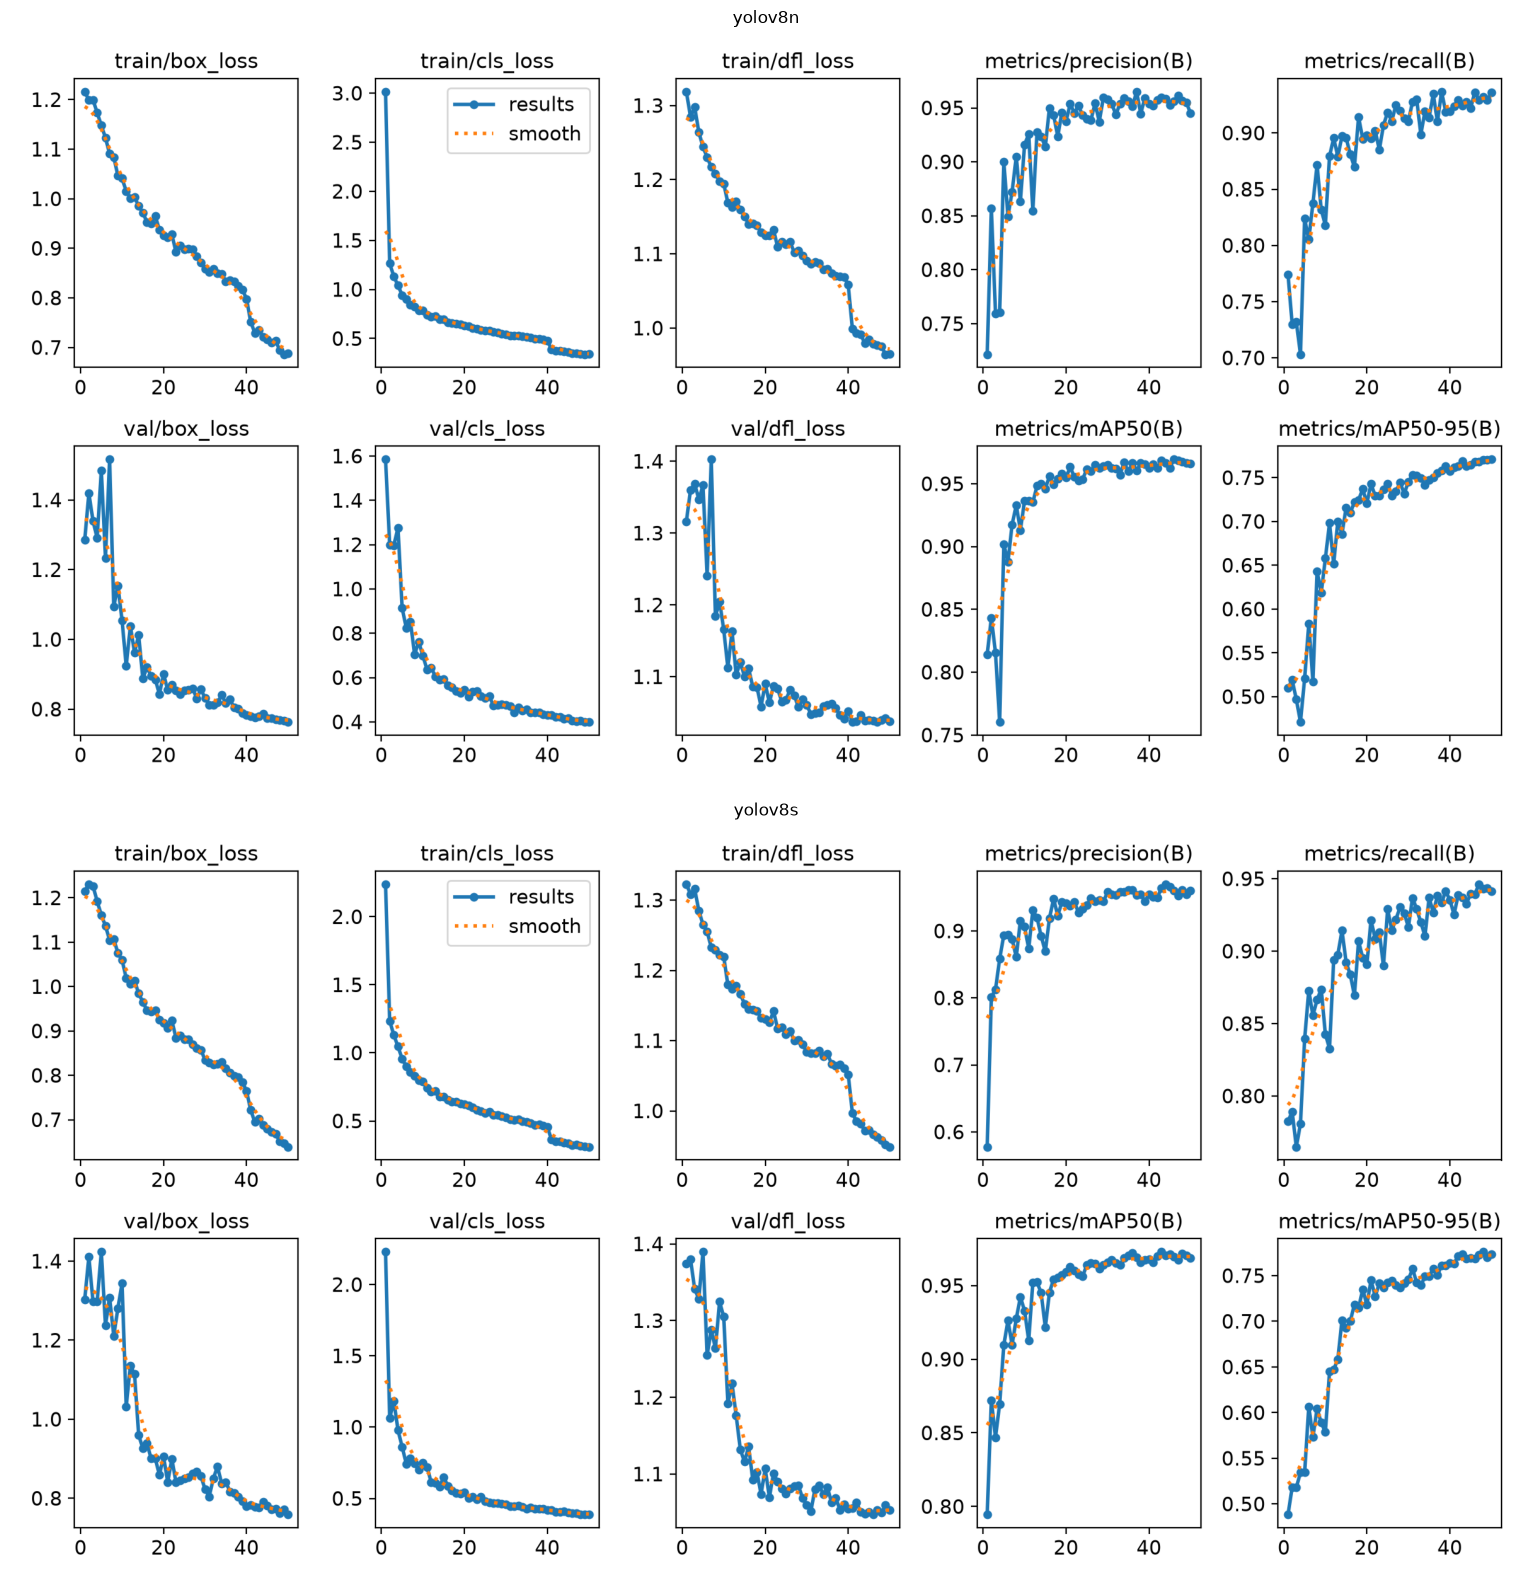

In [38]:
fig, axes = plt.subplots(len(run_dirs), 1, figsize=(16, 8 * len(run_dirs)))
for ax, (name, run_dir) in zip(axes, run_dirs.items()):
    ax.imshow(plt.imread(run_dir / "results.png"))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [39]:
def best_val_map(run_dir):
    return pd.read_csv(run_dir / "results.csv")["metrics/mAP50-95(B)"].max()


val_scores = {name: best_val_map(run_dir) for name, run_dir in run_dirs.items()}
best_name = max(val_scores, key=val_scores.get)
best_model = YOLO(run_dirs[best_name] / "weights" / "best.pt")
print(best_name, val_scores)


def evaluate(model, split):
    return model.val(data=det_config["data"], split=split, imgsz=det_config["imgsz"], batch=det_config["batch"],
                     project=str(RUNS_DIR), name=f"{best_name}_{split}", exist_ok=True)


split_metrics = {split: evaluate(best_model, split) for split in ["val", "test"]}

yolov8s {'yolov8n': np.float64(0.77082), 'yolov8s': np.float64(0.776)}
Ultralytics 8.4.183 🚀 Python-3.11.17 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 7891MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2989.2±874.6 MB/s, size: 25.1 KB)
val: Scanning /home/kerymy/Study-DevAI/DiagnosticMultimodal/processed/yolo/labels/valid.cache... 786 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 786/786 549.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 10.2it/s 4.9s0.2s
                   all        786        866      0.963      0.942      0.973      0.773
                Glioma        193        224      0.948      0.888      0.937      0.712
            Meningioma        237        245      0.979      0.992      0.995       0.83
              No Tumor        122        122      0.992      0.965     

In [40]:
def metrics_table(metrics):
    box = metrics.box
    rows = {CLASS_NAMES[c]: box.class_result(i) for i, c in enumerate(box.ap_class_index)}
    rows["all"] = box.mean_results()
    return pd.DataFrame(rows, index=["precision", "recall", "mAP50", "mAP50-95"]).T


comparison = pd.concat({split: metrics_table(m) for split, m in split_metrics.items()}, axis=1).round(3)
comparison

val                             test                       
           precision recall  mAP50 mAP50-95 precision recall  mAP50 mAP50-95
Glioma         0.948  0.888  0.937    0.712     0.863  0.824  0.873    0.629
Meningioma     0.979  0.992  0.995    0.830     0.970  0.954  0.986    0.803
No Tumor       0.992  0.965  0.994    0.806     0.976  0.992  0.993    0.804
Pituitary      0.935  0.924  0.965    0.745     0.914  0.854  0.924    0.693
all            0.963  0.942  0.973    0.773     0.931  0.906  0.944    0.732

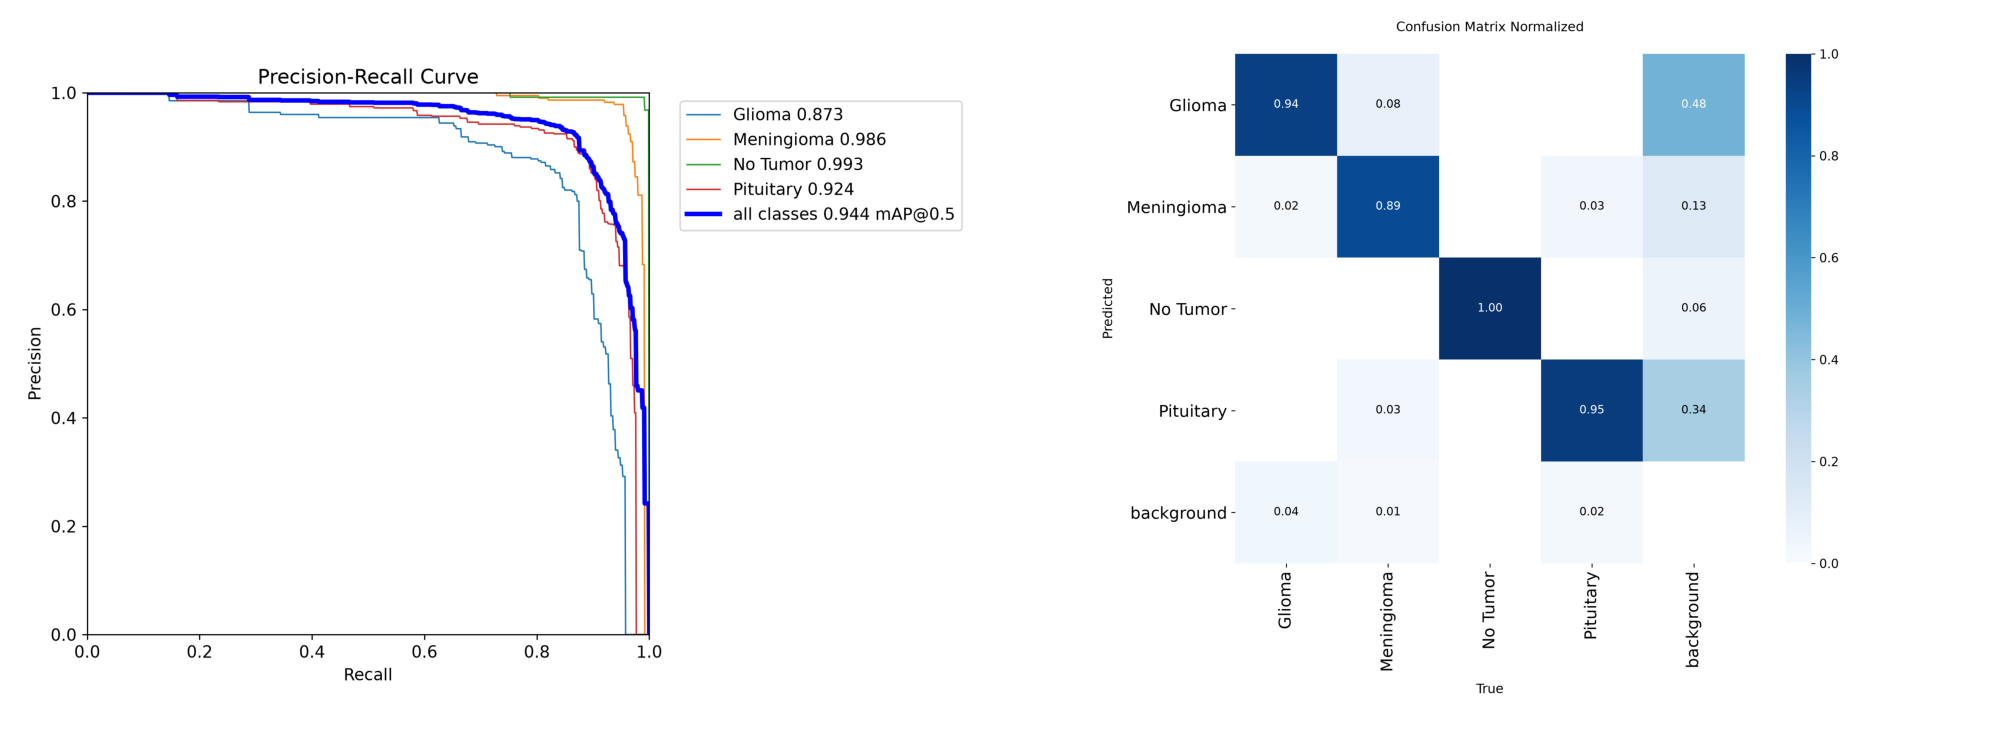

In [41]:
test_dir = Path(split_metrics["test"].save_dir)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, plot_name in zip(axes, ["BoxPR_curve.png", "confusion_matrix_normalized.png"]):
    ax.imshow(plt.imread(test_dir / plot_name))
    ax.axis("off")
plt.tight_layout()
plt.show()

In [42]:
import torch
from ultralytics.utils.metrics import box_iou
from ultralytics.utils.ops import xywh2xyxy

IOU_THRESHOLD = 0.5
TEST_IMAGES_DIR = YOLO_DIR / "images" / "test"
image_class = {image_path.name: image_path.parent.parent.name for image_path, _ in clean_pairs}


def test_label_path(image_path):
    return YOLO_DIR / "labels" / "test" / f"{image_path.stem}.txt"


def load_ground_truth(image_path, height, width):
    labels = torch.tensor(read_yolo_labels(test_label_path(image_path)))
    return labels[:, 0].long(), xywh2xyxy(labels[:, 1:] * torch.tensor([width, height, width, height]))


def image_status(gt_cls, gt_xyxy, pred_cls, pred_xyxy):
    if len(pred_cls) == 0:
        return "manqué"
    iou = box_iou(gt_xyxy, pred_xyxy)
    located = iou >= IOU_THRESHOLD
    same_class = gt_cls[:, None] == pred_cls[None, :]
    if not (iou > 0).any(dim=1).all():
        return "manqué"
    if not located.any(dim=1).all():
        return "mal localisé"
    if not (located & same_class).any(dim=1).all():
        return "mauvaise classe"
    if not located.any(dim=0).all():
        return "faux positif"
    return "correct"


records = []
for result in best_model.predict(str(TEST_IMAGES_DIR), imgsz=det_config["imgsz"], batch=det_config["batch"], stream=True, verbose=False):
    image_path = Path(result.path)
    gt_cls, gt_xyxy = load_ground_truth(image_path, *result.orig_shape)
    pred_cls, pred_xyxy = result.boxes.cls.cpu().long(), result.boxes.xyxy.cpu()
    records.append({
        "image": image_path,
        "class": image_class[image_path.name],
        "status": image_status(gt_cls, gt_xyxy, pred_cls, pred_xyxy),
        "predictions": list(zip(pred_cls.tolist(), result.boxes.conf.cpu().tolist(), pred_xyxy.tolist())),
    })

predictions_df = pd.DataFrame(records)
pd.crosstab(predictions_df["class"], predictions_df["status"], margins=True)

status,correct,faux positif,mal localisé,manqué,mauvaise classe,All
class,,,,,,
Glioma,141,25,13,13,1,193
Meningioma,211,9,3,8,6,237
No Tumor,119,1,0,1,0,121
Pituitary,213,6,14,0,1,234
All,684,41,30,22,8,785


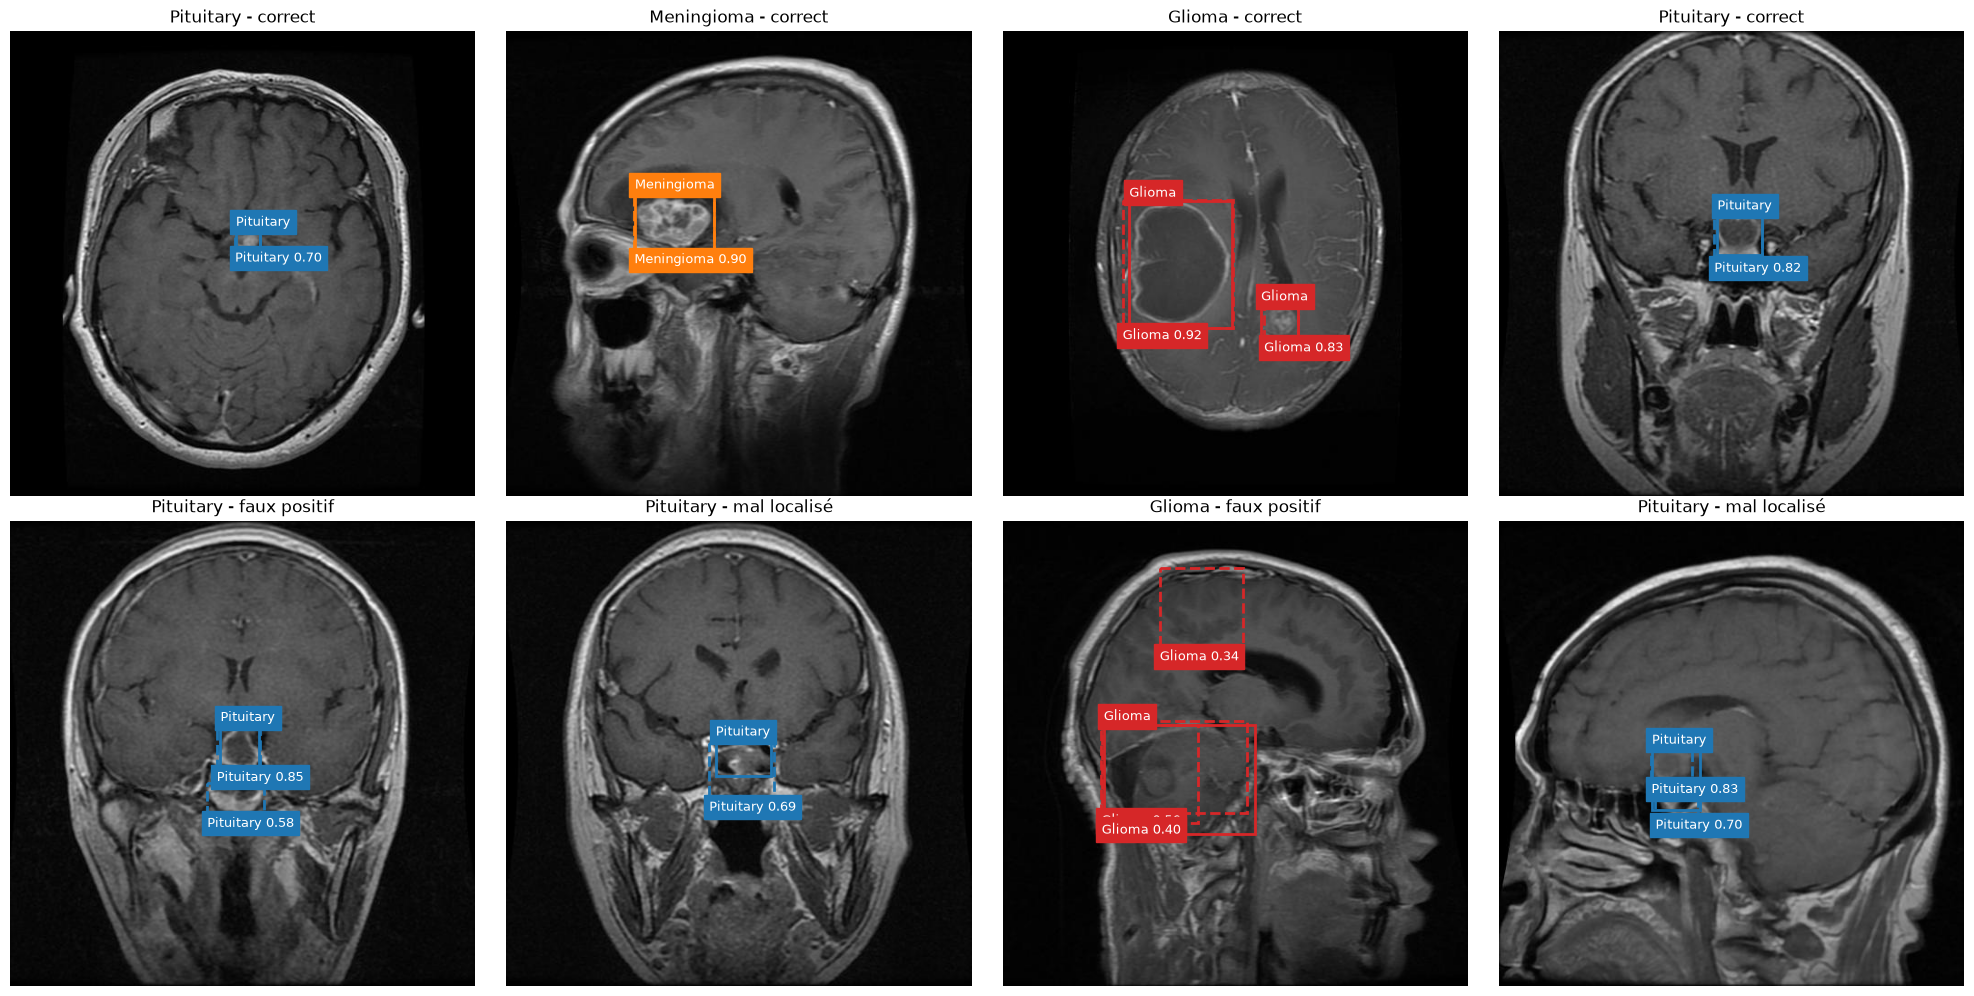

In [43]:
def draw_predictions(ax, record):
    draw_boxes(ax, record["image"], test_label_path(record["image"]))
    for cls, conf, (x1, y1, x2, y2) in record["predictions"]:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=COLORS[cls], linewidth=2, linestyle="--"))
        ax.text(x1, y2 + 12, f"{CLASS_NAMES[cls]} {conf:.2f}", color="white", fontsize=9, backgroundcolor=COLORS[cls])
    ax.set_title(f"{record['class']} - {record['status']}")


random.seed(42)
good = random.sample([r for r in records if r["status"] == "correct"], 4)
bad = random.sample([r for r in records if r["status"] != "correct"], 4)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, record in zip(axes.flat, good + bad):
    draw_predictions(ax, record)
plt.tight_layout()
plt.show()

In [44]:
best_run_id = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string=f"tags.mlflow.runName = '{best_name}'")["run_id"].iloc[0]
test_results = metrics_table(split_metrics["test"]).loc["all"]

with mlflow.start_run(run_id=best_run_id):
    mlflow.log_metrics({f"test/{name}": value for name, value in test_results.items()})
    mlflow.log_text(comparison.to_string(), "test/metrics_by_class.txt")
    mlflow.log_artifacts(str(test_dir), artifact_path="test")

In [45]:
import json

MODELS_DIR = PROJECT_ROOT / "models"
DETECTOR_PATH = MODELS_DIR / "detector.pt"
DETECTOR_META_PATH = MODELS_DIR / "detector_meta.json"
DETECTOR_ARTIFACTS_DIR = MODELS_DIR / "detector"
DETECTOR_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(run_dirs[best_name] / "weights" / "best.pt", DETECTOR_PATH)
shutil.copy2(DATA_YAML, DETECTOR_ARTIFACTS_DIR / "data.yaml")
shutil.copy2(run_dirs[best_name] / "results.png", DETECTOR_ARTIFACTS_DIR / "results.png")
for plot_name in ["BoxPR_curve.png", "confusion_matrix_normalized.png"]:
    shutil.copy2(test_dir / plot_name, DETECTOR_ARTIFACTS_DIR / f"test_{plot_name}")
comparison.to_csv(DETECTOR_ARTIFACTS_DIR / "metrics_by_class.csv")

meta = {
    "class_names": CLASS_NAMES,
    "img_size": det_config["imgsz"],
    "config": best_name,
    "mlflow_run_id": best_run_id,
    "test_metrics": {k: round(v, 4) for k, v in test_results.items()},
}
DETECTOR_META_PATH.write_text(json.dumps(meta, indent=2, ensure_ascii=False))

with mlflow.start_run(run_id=best_run_id):
    mlflow.log_artifact(str(DETECTOR_META_PATH))

print(DETECTOR_PATH, f"({DETECTOR_PATH.stat().st_size // 2**20} MB)")

/home/kerymy/Study-DevAI/DiagnosticMultimodal/models/detector.pt (21 MB)


Prédictions identiques : True


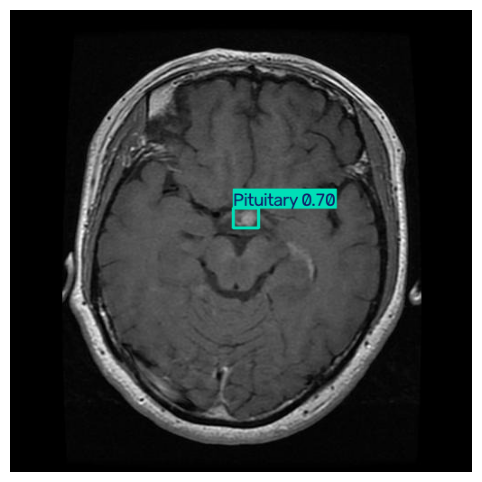

In [46]:
reloaded = YOLO(DETECTOR_PATH)
record = good[0]
result = reloaded.predict(record["image"], imgsz=det_config["imgsz"], verbose=False)[0]

same = torch.allclose(result.boxes.xyxy.cpu(), torch.tensor([box for _, _, box in record["predictions"]]), atol=1)
print("Prédictions identiques :", same)

plt.figure(figsize=(6, 6))
plt.imshow(result.plot()[..., ::-1])
plt.axis("off")
plt.show()

In [47]:
detection_runs = mlflow.search_runs(experiment_names=[EXPERIMENT])
client = mlflow.MlflowClient()

for run_name, run_id in zip(detection_runs["tags.mlflow.runName"], detection_runs["run_id"]):
    with mlflow.start_run(run_id=run_id):
        mlflow.log_artifact(str(DATA_YAML))
    print(run_name, "data.yaml" in [a.path for a in client.list_artifacts(run_id)])

yolov8s True
yolov8n True


In [48]:
DET_COLUMNS = {
    "metrics.metrics/precisionB": "val_precision",
    "metrics.metrics/recallB": "val_recall",
    "metrics.metrics/mAP50B": "val_mAP50",
    "metrics.metrics/mAP50-95B": "val_mAP50-95",
}

det_runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.`metrics/mAP50-95B` DESC"])
det_runs.set_index("tags.mlflow.runName")[list(DET_COLUMNS)].rename(columns=DET_COLUMNS).round(3)

,val_precision,val_recall,val_mAP50,val_mAP50-95
tags.mlflow.runName,,,,
yolov8s,0.962,0.943,0.972,0.775
yolov8n,0.946,0.936,0.966,0.771


In [49]:
from datetime import date

from mlflow.models import ModelSignature
from mlflow.types import ColSpec, Schema

DETECTOR_NAME = "brain-tumor-detector"
DETECTION_COLUMNS = {"image_path": "string", "class": "string", "confidence": "double",
                     "x1": "double", "y1": "double", "x2": "double", "y2": "double"}


class YoloDetector(mlflow.pyfunc.PythonModel):
    def load_context(self, context):
        from ultralytics import YOLO
        self.model = YOLO(context.artifacts["weights"])

    def predict(self, context, model_input, params=None):
        rows = []
        for image_path in model_input["image_path"]:
            result = self.model.predict(image_path, verbose=False)[0]
            for cls, conf, box in zip(result.boxes.cls.tolist(), result.boxes.conf.tolist(), result.boxes.xyxy.tolist()):
                rows.append({"image_path": image_path, "class": result.names[int(cls)], "confidence": conf,
                             "x1": box[0], "y1": box[1], "x2": box[2], "y2": box[3]})
        return pd.DataFrame(rows, columns=list(DETECTION_COLUMNS))


signature = ModelSignature(
    inputs=Schema([ColSpec("string", "image_path")]),
    outputs=Schema([ColSpec(dtype, name) for name, dtype in DETECTION_COLUMNS.items()]),
)
det_meta = json.loads(DETECTOR_META_PATH.read_text())
det_test = det_meta["test_metrics"]

with mlflow.start_run(run_id=det_meta["mlflow_run_id"]):
    det_info = mlflow.pyfunc.log_model(
        name="detector",
        python_model=YoloDetector(),
        artifacts={"weights": str(DETECTOR_PATH)},
        signature=signature,
    )

det_version = mlflow.register_model(det_info.model_uri, DETECTOR_NAME)
client.update_registered_model(DETECTOR_NAME, description="Détection de tumeurs cérébrales sur IRM (YOLOv8)")
client.update_model_version(
    DETECTOR_NAME, det_version.version,
    description=(f"Run {det_meta['mlflow_run_id']} ({det_meta['config']}) - test mAP50 {det_test['mAP50']}, "
                 f"mAP50-95 {det_test['mAP50-95']}, recall {det_test['recall']} - enregistré le {date.today()}"),
)
for key, value in {"task": "detection", "framework": "ultralytics", "config": det_meta["config"]}.items():
    client.set_model_version_tag(DETECTOR_NAME, det_version.version, key, value)
client.set_registered_model_alias(DETECTOR_NAME, "champion", det_version.version)

/home/kerymy/Study-DevAI/DiagnosticMultimodal/.venv/lib/python3.11/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
2026/10/27 16:05:57 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
/home/kerymy/Study-DevAI/DiagnosticMultimodal/.venv/lib/python3.11/site-packages/mlflow/pyfunc/__init__.py:3344: UserWarning: An input example was not provided when logging the model. To ensure the model signature functions correctly, 

In [50]:
champion = mlflow.pyfunc.load_model(f"models:/{DETECTOR_NAME}@champion")
print("Run source :", champion.metadata.run_id)

champion.predict(pd.DataFrame({"image_path": [str(record["image"]) for record in good]}))

Run source : b5d73b07745745e5a08cb932b9033b7f


,image_path,class,confidence,x1,y1,x2,y2
0,/home/kerymy/Study-DevAI/DiagnosticMultimodal/...,Pituitary,0.701091,247.031219,219.478882,275.033600,241.382507
1,/home/kerymy/Study-DevAI/DiagnosticMultimodal/...,Meningioma,0.898649,140.429993,177.508759,227.964233,243.074951
2,/home/kerymy/Study-DevAI/DiagnosticMultimodal/...,Glioma,0.924127,131.725739,185.412567,253.157562,326.630463
3,/home/kerymy/Study-DevAI/DiagnosticMultimodal/...,Glioma,0.830445,287.321289,300.771790,324.327271,340.141174
4,/home/kerymy/Study-DevAI/DiagnosticMultimodal/...,Pituitary,0.821307,236.595398,199.126862,289.572510,252.592987
